In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [24]:
path = "../0_Data/1_Rietveld/SPring-8/Mafic/SP-MTN-46/SP-MTN-46.dia"
position = 3000

df = pd.read_csv(
    path,
    sep=r"\s+",
    skiprows=1,
    header=None,
)
df.index = df[0]

# colを取得
df_col = pd.read_csv(path, sep=r"\s+", header=None,).iloc[0]
df_col = df_col.iloc[1:].str.split("=", n=1, expand=True)
df_col = df_col.set_index(0)

# Initial部分のcolをまとめる
col_initial = ["2 theta", "Observesd", "calculated", "Background"]
# それ以降についてくっつける
col_mineral_curve = df_col.iloc[7:, 0].tolist()
col_all = col_initial + col_mineral_curve

# dfに入れる
df.columns = col_all
# differenceを追加する
df["difference"] = df["Observesd"] - df["calculated"] - position

df_add_bckg = df.copy()
df_add_bckg[col_mineral_curve] = df_add_bckg[col_mineral_curve].add(df["Background"], axis=0)

<Axes: xlabel='0'>

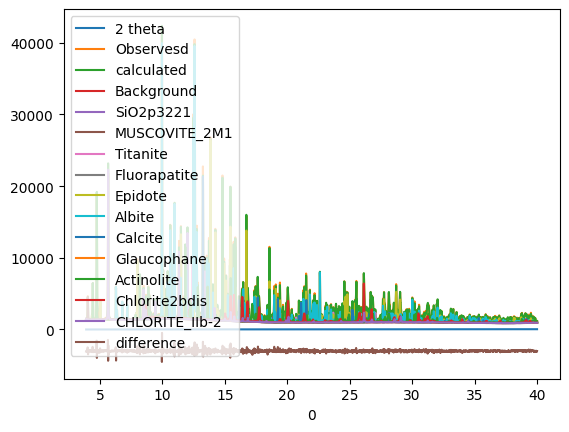

In [26]:
df_add_bckg.plot()

# plt.xlim(9.90, 10)

In [23]:
df[[1,2,3,]].plot()
plt.xlim(9.90, 10)

KeyError: "None of [Index([1, 2, 3], dtype='int64')] are in the [columns]"